# Proyecto II — Destilado de Modelos para Detección de Anomalías

**Curso de Inteligencia Artificial · Instituto Tecnológico de Costa Rica**

Implementa tres modelos sobre el dataset MVTec AD:
- **Modelo A**: Clasificador CNN (ResNet-18 conv1–conv3) entrenado desde cero
- **Modelo B**: Mismo clasificador entrenado con destilado *teacher-student* (ResNet-18 preentrenado)
- **Modelo C**: Autoencoder U-Net entrenado desde cero

Los embeddings de cada modelo se usan para detección de anomalías (Mahalanobis) y análisis DBSCAN.

## 0 · Dataset MVTec AD

In [1]:
import sys
import os
from pathlib import Path
import kagglehub

ROOT     = Path('..').resolve()
DATA_DIR = ROOT / 'data' / 'mvtec'

if not (DATA_DIR / 'bottle').exists():
    print('Descargando MVTec AD desde Kaggle...')
    path = Path(kagglehub.dataset_download('ipythonx/mvtec-ad'))
    print(f'Descargado en: {path}')

    actual = path
    if not (actual / 'bottle').exists():
        for sub in sorted(path.iterdir()):
            if sub.is_dir() and (sub / 'bottle').exists():
                actual = sub
                break

    DATA_DIR.parent.mkdir(parents=True, exist_ok=True)
    if not DATA_DIR.exists():
        DATA_DIR.symlink_to(actual)
    print(f'Symlink: {DATA_DIR} -> {actual}')
else:
    print(f'Dataset ya disponible en {DATA_DIR}')

CLASSES = ['bottle', 'cable', 'capsule', 'carpet', 'grid',
           'hazelnut', 'leather', 'metal_nut', 'pill', 'screw']
missing = [c for c in CLASSES if not (DATA_DIR / c / 'train' / 'good').exists()]
if missing:
    print(f'ADVERTENCIA — clases faltantes: {missing}')
else:
    total = sum(len(list((DATA_DIR / c / 'train' / 'good').glob('*.png'))) for c in CLASSES)
    print(f'OK — {len(CLASSES)} clases, {total} imágenes normales de entrenamiento')

Dataset ya disponible en /home/allandbb/Documents/GitHub/nomaly-detection-distillation/data/mvtec
OK — 10 clases, 2639 imágenes normales de entrenamiento


/home/allandbb/Documents/GitHub/nomaly-detection-distillation/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1 · Imports y configuración

In [2]:
sys.path.insert(0, '..')

import glob
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torchvision
import pytorch_lightning as pl
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint
from pytorch_lightning.loggers import WandbLogger
from omegaconf import OmegaConf
import wandb
from hydra import initialize, compose
from hydra.core.global_hydra import GlobalHydra

from src.data.mvtec_datamodule import MVTecDataModule
from src.models.cnn_scratch import CNNScratchModule
from src.models.cnn_distilled import CNNDistilledModule
from src.models.unet_autoencoder import UNetAutoencoderModule
from src.utils.metrics_callback import MetricsHistory
from src.utils.anomaly_detection import (
    extract_embeddings, extract_recon_errors,
    fit_per_class_params, per_class_mahalanobis_scores,
    find_threshold, evaluate_anomaly_detection, get_roc_curve,
)
from src.utils.clustering import (
    reduce_pca, reduce_tsne, run_dbscan, tune_dbscan,
    dbscan_anomaly_metrics, plot_2d_embeddings,
)

os.makedirs('../outputs', exist_ok=True)
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
torch.set_float32_matmul_precision('medium')
pl.seed_everything(42, workers=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'PyTorch {torch.__version__} | Lightning {pl.__version__} | Device: {DEVICE}')

Seed set to 42


PyTorch 2.12.1+cu130 | Lightning 2.6.5 | Device: cuda


In [3]:
# Hydra config (se inicializa una sola vez para toda la sesión)
GlobalHydra.instance().clear()
with initialize(config_path='../conf', version_base=None):
    cfg = compose(config_name='config', overrides=['model=cnn_scratch'])

DATASET_PATH = str(DATA_DIR)
IMAGE_SIZE   = cfg.data.image_size
NUM_WORKERS  = cfg.data.num_workers
VAL_SPLIT    = cfg.data.val_split

print(OmegaConf.to_yaml(cfg))

model:
  name: cnn_scratch
  hidden_dim: 256
  num_classes: 10
  learning_rate: 0.001
  weight_decay: 0.0001
trainer:
  max_epochs: 50
  accelerator: auto
  devices: 1
  precision: 32
  early_stopping:
    monitor: val_loss
    patience: 10
    mode: min
    min_delta: 0.0001
  checkpoint:
    monitor: val_loss
    mode: min
    save_top_k: 1
logger:
  project: anomaly-detection-distillation
  entity: null
  log_model: false
  save_dir: ./wandb_logs
data:
  dataset_path: ./data/mvtec
  classes:
  - bottle
  - cable
  - capsule
  - carpet
  - grid
  - hazelnut
  - leather
  - metal_nut
  - pill
  - screw
  image_size: 256
  batch_size: 32
  num_workers: 4
  val_split: 0.2
seed: 42
output_dir: ./outputs
checkpoints_dir: ./checkpoints



In [4]:
# WandB login (una sola vez)
try:
    wandb.login()
except Exception:
    os.environ['WANDB_MODE'] = 'offline'
    print('WandB offline mode activado.')

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/allandbb/.netrc.


wandb: Currently logged in as: adbyb-es (ai-allan-david) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


## 2 · Modelo A — CNN desde cero (Scratch)

Clasificador CNN con arquitectura ResNet-18 (conv1, conv2_x, conv3_x) + cabeza FC.  
Pesos inicializados aleatoriamente. Se prueban **3 configuraciones de hiperparámetros**.

In [5]:
HYPERPARAMS_A = [
    dict(run_name='scratch-lr1e3-hd256', learning_rate=1e-3, weight_decay=1e-4, hidden_dim=256, batch_size=32, max_epochs=50),
    dict(run_name='scratch-lr5e4-hd512', learning_rate=5e-4, weight_decay=1e-4, hidden_dim=512, batch_size=32, max_epochs=50),
    dict(run_name='scratch-lr1e4-hd128', learning_rate=1e-4, weight_decay=1e-5, hidden_dim=128, batch_size=64, max_epochs=60),
]


def build_callbacks(ckpt_dir: str):
    early_stop = EarlyStopping(
        monitor='val_loss', patience=cfg.trainer.early_stopping.patience,
        mode='min', min_delta=cfg.trainer.early_stopping.min_delta, verbose=True,
    )
    checkpoint = ModelCheckpoint(
        dirpath=ckpt_dir, filename='best-{epoch:02d}-{val_loss:.4f}',
        monitor='val_loss', mode='min', save_top_k=1, verbose=True,
    )
    history = MetricsHistory()
    return [early_stop, checkpoint, history], history


def train_run_a(hp: dict):
    print(f"\n{'='*60}\nRun: {hp['run_name']}\n{'='*60}")
    dm = MVTecDataModule(
        dataset_path=DATASET_PATH, classes=CLASSES, image_size=IMAGE_SIZE,
        batch_size=hp['batch_size'], num_workers=NUM_WORKERS, val_split=VAL_SPLIT,
    )
    model = CNNScratchModule(
        num_classes=len(CLASSES), hidden_dim=hp['hidden_dim'],
        learning_rate=hp['learning_rate'], weight_decay=hp['weight_decay'],
    )
    logger = WandbLogger(project=cfg.logger.project, name=hp['run_name'], log_model=False, save_dir='../wandb_logs')
    logger.experiment.config.update(hp)
    callbacks, history = build_callbacks(f"../checkpoints/cnn_scratch/{hp['run_name']}")
    trainer = pl.Trainer(
        max_epochs=hp['max_epochs'], accelerator=cfg.trainer.accelerator, devices=cfg.trainer.devices,
        callbacks=callbacks, logger=logger, log_every_n_steps=10, deterministic=True,
    )
    trainer.fit(model, dm)
    wandb.finish()
    return trainer, model, dm, history

In [6]:
results_a = []
for hp in HYPERPARAMS_A:
    trainer, model, dm, history = train_run_a(hp)
    val_loss = float(trainer.callback_metrics.get('val_loss', float('inf')))
    val_acc  = float(trainer.callback_metrics.get('val_acc', 0.0))
    results_a.append({'run_name': hp['run_name'], 'val_loss': val_loss, 'val_acc': val_acc, 'hp': hp, 'history': history})
    print(f"[{hp['run_name']}] val_loss={val_loss:.4f} | val_acc={val_acc:.4f}")

df_a = pd.DataFrame([{'run': r['run_name'], 'val_loss': r['val_loss'], 'val_acc': r['val_acc']} for r in results_a])
df_a = df_a.sort_values('val_loss')
print('\n=== Resumen Modelo A (Scratch) ===')
print(df_a.to_string(index=False))

wandb: WARNING The anonymous setting has no effect and will be removed in a future version.



Run: scratch-lr1e3-hd256


wandb: setting up run 6gep6uz2


wandb: Tracking run with wandb version 0.28.0


wandb: Run data is saved locally in ../wandb_logs/wandb/run-20260625_165322-6gep6uz2
wandb: Run `wandb offline` to turn off syncing.


...

wandb: uploading data


wandb: 
wandb: Run history:
wandb:               epoch ▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇████
wandb:           train_acc ▁▆▇█████████████████████████████████████
wandb:          train_loss █▅▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb: trainer/global_step ▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇█████
wandb:             val_acc ▁▅▅█▅██▇█▅██████████████████████████████
wandb:            val_loss █▄▃▂▂▁▁▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb: 
wandb: Run summary:
wandb:               epoch 48
wandb:           train_acc 1
wandb:          train_loss 0.00481
wandb: trainer/global_step 1616
wandb:             val_acc 1
wandb:            val_loss 0.00024
wandb: 


wandb: 🚀 View run scratch-lr1e4-hd128 at: https://wandb.ai/ai-allan-david/anomaly-detection-distillation/runs/8lnwmqgk
wandb: ⭐️ View project at: https://wandb.ai/ai-allan-david/anomaly-detection-distillation
wandb: Synced 4 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)


wandb: Find logs at: ../wandb_logs/wandb/run-20260625_172338-8lnwmqgk/logs


[scratch-lr1e4-hd128] val_loss=0.0002 | val_acc=1.0000

=== Resumen Modelo A (Scratch) ===
                run  val_loss  val_acc
scratch-lr5e4-hd512  0.000035      1.0
scratch-lr1e4-hd128  0.000242      1.0
scratch-lr1e3-hd256  0.001690      1.0


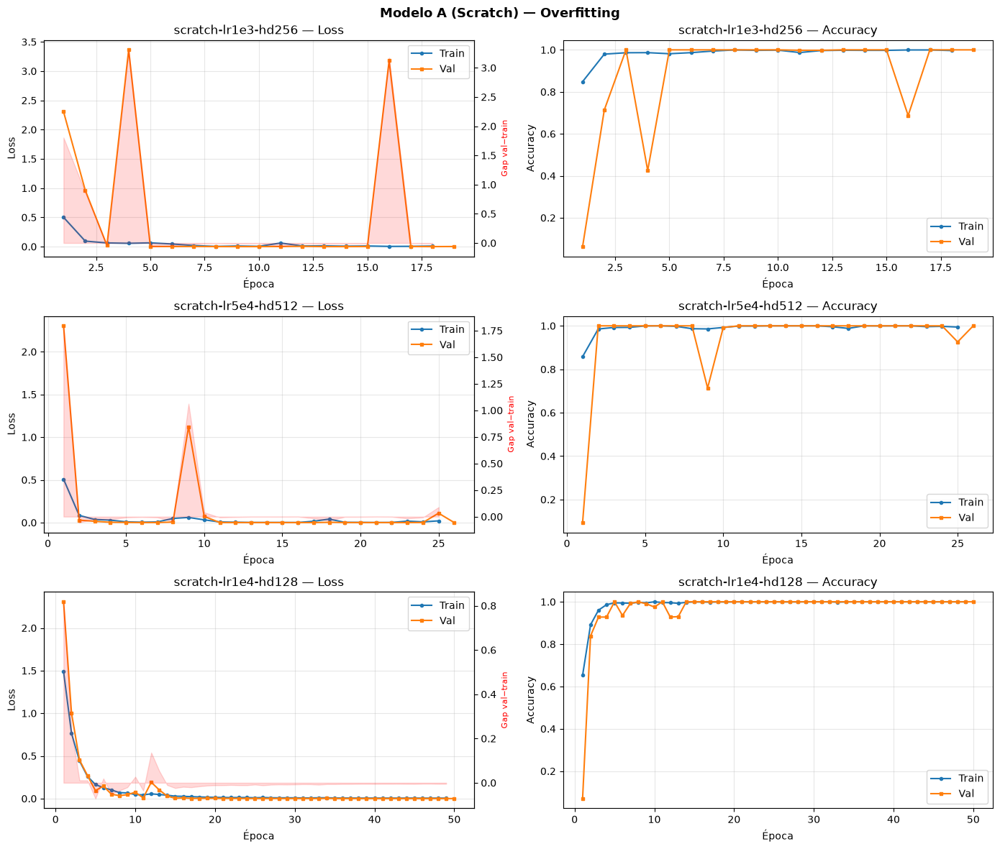

In [7]:
fig, axes = plt.subplots(len(results_a), 2, figsize=(14, 4 * len(results_a)))
if len(results_a) == 1:
    axes = [axes]

for i, r in enumerate(results_a):
    h = r['history']
    axes[i][0].plot(range(1, len(h.train_loss)+1), h.train_loss, label='Train', marker='o', ms=3)
    axes[i][0].plot(range(1, len(h.val_loss)+1),   h.val_loss,   label='Val',   marker='s', ms=3)
    n = min(len(h.train_loss), len(h.val_loss))
    gap = [v - t for t, v in zip(h.train_loss[:n], h.val_loss[:n])]
    ax2 = axes[i][0].twinx()
    ax2.fill_between(range(1, n+1), gap, alpha=0.15, color='red')
    ax2.set_ylabel('Gap val−train', color='red', fontsize=8)
    axes[i][0].set_title(f"{r['run_name']} — Loss")
    axes[i][0].set_xlabel('Época'); axes[i][0].set_ylabel('Loss')
    axes[i][0].legend(); axes[i][0].grid(True, alpha=0.3)
    if h.train_acc:
        axes[i][1].plot(range(1, len(h.train_acc)+1), h.train_acc, label='Train', marker='o', ms=3)
        axes[i][1].plot(range(1, len(h.val_acc)+1),   h.val_acc,   label='Val',   marker='s', ms=3)
        axes[i][1].set_title(f"{r['run_name']} — Accuracy")
        axes[i][1].set_xlabel('Época'); axes[i][1].set_ylabel('Accuracy')
        axes[i][1].legend(); axes[i][1].grid(True, alpha=0.3)

plt.suptitle('Modelo A (Scratch) — Overfitting', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/overfitting_cnn_scratch.png', dpi=150)
plt.show()

## 3 · Modelo B — CNN con Destilado (Teacher-Student)

**Teacher:** ResNet-18 preentrenado en ImageNet (pesos congelados).  
**Student:** Misma arquitectura CNN que Modelo A.

Pérdida combinada: `α·CE + β·feat_loss(conv2_x) + γ·feat_loss(conv3_x)`  
Se prueban **3 configuraciones de hiperparámetros**.

In [8]:
HYPERPARAMS_B = [
    dict(run_name='distil-a5b3g2-lr1e3', learning_rate=1e-3, weight_decay=1e-4,
         hidden_dim=256, batch_size=32, max_epochs=50, alpha=0.5, beta=0.3, gamma=0.2),
    dict(run_name='distil-a7b2g1-lr5e4', learning_rate=5e-4, weight_decay=1e-4,
         hidden_dim=256, batch_size=32, max_epochs=50, alpha=0.7, beta=0.2, gamma=0.1),
    dict(run_name='distil-a3b4g3-lr1e4', learning_rate=1e-4, weight_decay=1e-5,
         hidden_dim=512, batch_size=64, max_epochs=60, alpha=0.3, beta=0.4, gamma=0.3),
]


def train_run_b(hp: dict):
    print(f"\n{'='*60}\nRun: {hp['run_name']}\n{'='*60}")
    dm = MVTecDataModule(
        dataset_path=DATASET_PATH, classes=CLASSES, image_size=IMAGE_SIZE,
        batch_size=hp['batch_size'], num_workers=NUM_WORKERS, val_split=VAL_SPLIT,
    )
    model = CNNDistilledModule(
        num_classes=len(CLASSES), hidden_dim=hp['hidden_dim'],
        learning_rate=hp['learning_rate'], weight_decay=hp['weight_decay'],
        alpha=hp['alpha'], beta=hp['beta'], gamma=hp['gamma'],
    )
    logger = WandbLogger(project=cfg.logger.project, name=hp['run_name'], log_model=False, save_dir='../wandb_logs')
    logger.experiment.config.update(hp)
    callbacks, history = build_callbacks(f"../checkpoints/cnn_distilled/{hp['run_name']}")
    trainer = pl.Trainer(
        max_epochs=hp['max_epochs'], accelerator=cfg.trainer.accelerator, devices=cfg.trainer.devices,
        callbacks=callbacks, logger=logger, log_every_n_steps=10, deterministic=True,
    )
    trainer.fit(model, dm)
    wandb.finish()
    return trainer, model, dm, history

In [9]:
results_b = []
for hp in HYPERPARAMS_B:
    trainer, model, dm, history = train_run_b(hp)
    val_loss = float(trainer.callback_metrics.get('val_loss', float('inf')))
    val_acc  = float(trainer.callback_metrics.get('val_acc', 0.0))
    results_b.append({'run_name': hp['run_name'], 'val_loss': val_loss, 'val_acc': val_acc,
                      'alpha': hp['alpha'], 'beta': hp['beta'], 'gamma': hp['gamma'],
                      'hp': hp, 'history': history})
    print(f"[{hp['run_name']}] val_loss={val_loss:.4f} | val_acc={val_acc:.4f}")

df_b = pd.DataFrame([{'run': r['run_name'], 'val_loss': r['val_loss'], 'val_acc': r['val_acc'],
                       'alpha': r['alpha'], 'beta': r['beta'], 'gamma': r['gamma']} for r in results_b])
df_b = df_b.sort_values('val_loss')
print('\n=== Resumen Modelo B (Destilado) ===')
print(df_b.to_string(index=False))


Run: distil-a5b3g2-lr1e3


wandb: setting up run mjahsjv1


wandb: Tracking run with wandb version 0.28.0


wandb: Run data is saved locally in ../wandb_logs/wandb/run-20260625_175803-mjahsjv1
wandb: Run `wandb offline` to turn off syncing.


wandb: Syncing run distil-a5b3g2-lr1e3


...

wandb: uploading history steps 110-111, summary


wandb: 
wandb: Run history:
wandb:               epoch ▁▁▁▁▁▂▂▂▂▂▃▃▃▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇██
wandb:           train_acc ▁▅██████████████████████████████████████
wandb:       train_ce_loss █▅▄▃▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:     train_feat_loss █▇▆▅▅▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:          train_loss █▆▄▄▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb: trainer/global_step ▁▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇██
wandb:             val_acc ▁███▇███████████████████████████████████
wandb:            val_loss █▅▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb: 
wandb: Run summary:
wandb:               epoch 55
wandb:           train_acc 1
wandb:       train_ce_loss 0.02309
wandb:     train_feat_loss 0.06818
wandb:          train_loss 0.02886
wandb: trainer/global_step 1847
wandb:             val_acc 1
wandb:            val_loss 0.01317
wandb: 


wandb: 🚀 View run distil-a3b4g3-lr1e4 at: https://wandb.ai/ai-allan-david/anomaly-detection-distillation/runs/oau96wbe
wandb: ⭐️ View project at: https://wandb.ai/ai-allan-david/anomaly-detection-distillation
wandb: Synced 4 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)


wandb: Find logs at: ../wandb_logs/wandb/run-20260625_185305-oau96wbe/logs


[distil-a3b4g3-lr1e4] val_loss=0.0132 | val_acc=1.0000

=== Resumen Modelo B (Destilado) ===
                run  val_loss  val_acc  alpha  beta  gamma
distil-a5b3g2-lr1e3  0.000498      1.0    0.5   0.3    0.2
distil-a7b2g1-lr5e4  0.000771      1.0    0.7   0.2    0.1
distil-a3b4g3-lr1e4  0.013167      1.0    0.3   0.4    0.3


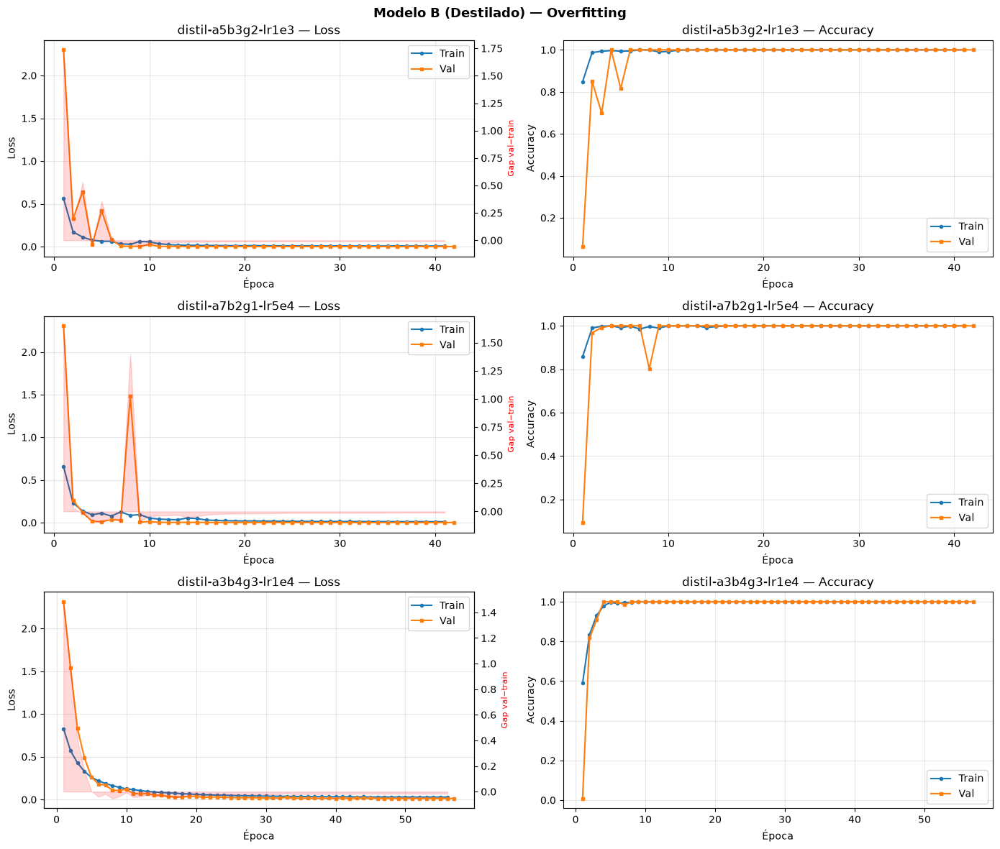

In [10]:
fig, axes = plt.subplots(len(results_b), 2, figsize=(14, 4 * len(results_b)))
if len(results_b) == 1:
    axes = [axes]

for i, r in enumerate(results_b):
    h = r['history']
    axes[i][0].plot(range(1, len(h.train_loss)+1), h.train_loss, label='Train', marker='o', ms=3)
    axes[i][0].plot(range(1, len(h.val_loss)+1),   h.val_loss,   label='Val',   marker='s', ms=3)
    n = min(len(h.train_loss), len(h.val_loss))
    gap = [v - t for t, v in zip(h.train_loss[:n], h.val_loss[:n])]
    ax2 = axes[i][0].twinx()
    ax2.fill_between(range(1, n+1), gap, alpha=0.15, color='red')
    ax2.set_ylabel('Gap val−train', color='red', fontsize=8)
    axes[i][0].set_title(f"{r['run_name']} — Loss")
    axes[i][0].set_xlabel('Época'); axes[i][0].set_ylabel('Loss')
    axes[i][0].legend(); axes[i][0].grid(True, alpha=0.3)
    if h.train_acc:
        axes[i][1].plot(range(1, len(h.train_acc)+1), h.train_acc, label='Train', marker='o', ms=3)
        axes[i][1].plot(range(1, len(h.val_acc)+1),   h.val_acc,   label='Val',   marker='s', ms=3)
        axes[i][1].set_title(f"{r['run_name']} — Accuracy")
        axes[i][1].set_xlabel('Época'); axes[i][1].set_ylabel('Accuracy')
        axes[i][1].legend(); axes[i][1].grid(True, alpha=0.3)

plt.suptitle('Modelo B (Destilado) — Overfitting', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/overfitting_cnn_distilled.png', dpi=150)
plt.show()

## 4 · Modelo C — Autoencoder U-Net (desde cero)

Autoencoder U-Net entrenado para **reconstruir** imágenes normales.  
El embedding del bottleneck y el error de reconstrucción MSE se usan como scores de anomalía.  
Se prueban **3 configuraciones de hiperparámetros**.

In [11]:
HYPERPARAMS_C = [
    dict(run_name='unet-f64-128-256-512-lr1e4', learning_rate=1e-4, weight_decay=1e-5,
         features=[64, 128, 256, 512], embedding_dim=256, batch_size=4, max_epochs=50),
    dict(run_name='unet-f32-64-128-256-lr1e4',  learning_rate=1e-4, weight_decay=1e-5,
         features=[32, 64, 128, 256],  embedding_dim=128, batch_size=8, max_epochs=50),
    dict(run_name='unet-f64-128-256-512-lr5e5', learning_rate=5e-5, weight_decay=1e-5,
         features=[64, 128, 256, 512], embedding_dim=512, batch_size=4, max_epochs=60),
]


def train_run_c(hp: dict):
    print(f"\n{'='*60}\nRun: {hp['run_name']}\n{'='*60}")
    torch.cuda.empty_cache()
    dm = MVTecDataModule(
        dataset_path=DATASET_PATH, classes=CLASSES, image_size=IMAGE_SIZE,
        batch_size=hp['batch_size'], num_workers=NUM_WORKERS, val_split=VAL_SPLIT,
    )
    model = UNetAutoencoderModule(
        in_channels=3, features=hp['features'],
        embedding_dim=hp['embedding_dim'],
        learning_rate=hp['learning_rate'], weight_decay=hp['weight_decay'],
    )
    logger = WandbLogger(project=cfg.logger.project, name=hp['run_name'], log_model=False, save_dir='../wandb_logs')
    logger.experiment.config.update(hp)
    callbacks, history = build_callbacks(f"../checkpoints/unet/{hp['run_name']}")
    trainer = pl.Trainer(
        max_epochs=hp['max_epochs'], accelerator=cfg.trainer.accelerator, devices=cfg.trainer.devices,
        callbacks=callbacks, logger=logger, log_every_n_steps=10,
        precision='16-mixed',
    )
    trainer.fit(model, dm)
    wandb.finish()
    torch.cuda.empty_cache()
    return trainer, model, dm, history

In [12]:
results_c = []
for hp in HYPERPARAMS_C:
    trainer, model, dm, history = train_run_c(hp)
    val_loss = float(trainer.callback_metrics.get('val_loss', float('inf')))
    results_c.append({'run_name': hp['run_name'], 'val_loss': val_loss,
                      'hp': hp, 'model': model, 'dm': dm, 'history': history})
    print(f"[{hp['run_name']}] val_MSE={val_loss:.6f}")

df_c = pd.DataFrame([{'run': r['run_name'], 'val_mse': r['val_loss'],
                       'features': str(r['hp']['features']),
                       'embedding_dim': r['hp']['embedding_dim'],
                       'lr': r['hp']['learning_rate']} for r in results_c])
df_c = df_c.sort_values('val_mse')
print('\n=== Resumen Modelo C (U-Net) ===')
print(df_c.to_string(index=False))


Run: unet-f64-128-256-512-lr1e4


wandb: setting up run mqz4omvi


wandb: Tracking run with wandb version 0.28.0


wandb: Run data is saved locally in ../wandb_logs/wandb/run-20260625_192940-mqz4omvi
wandb: Run `wandb offline` to turn off syncing.


wandb: Syncing run unet-f64-128-256-512-lr1e4


...

wandb: uploading wandb-summary.json; uploading config.yaml


wandb: 
wandb: Run history:
wandb:               epoch ▁▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▅▅▆▆▆▆▇▇▇▇████
wandb:          train_loss █▄▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁
wandb: trainer/global_step ▁▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▅▅▆▆▆▆▇▇▇▇████
wandb:            val_loss █▂█▃▄▃▁▅▄▂▂▁▂▃▂▁▂
wandb: 
wandb: Run summary:
wandb:               epoch 16
wandb:          train_loss 0.03115
wandb: trainer/global_step 8975
wandb:            val_loss 0.009
wandb: 


wandb: 🚀 View run unet-f64-128-256-512-lr5e5 at: https://wandb.ai/ai-allan-david/anomaly-detection-distillation/runs/ku3j6vh1
wandb: ⭐️ View project at: https://wandb.ai/ai-allan-david/anomaly-detection-distillation
wandb: Synced 4 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)


wandb: Find logs at: ../wandb_logs/wandb/run-20260625_202750-ku3j6vh1/logs


[unet-f64-128-256-512-lr5e5] val_MSE=0.008998

=== Resumen Modelo C (U-Net) ===
                       run  val_mse            features  embedding_dim      lr
unet-f64-128-256-512-lr5e5 0.008998 [64, 128, 256, 512]            512 0.00005
 unet-f32-64-128-256-lr1e4 0.009503  [32, 64, 128, 256]            128 0.00010
unet-f64-128-256-512-lr1e4 0.012811 [64, 128, 256, 512]            256 0.00010


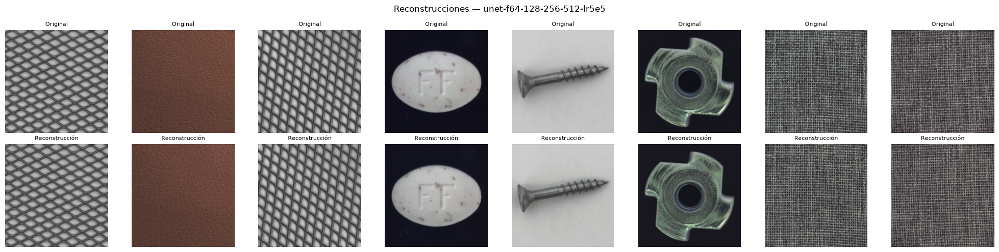

In [13]:
# Visualizar reconstrucciones del mejor modelo C
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def denormalize(t):
    return (t * IMAGENET_STD + IMAGENET_MEAN).clamp(0, 1)

best_c = results_c[df_c.index[0]]
best_model_c = best_c['model']
best_dm_c    = best_c['dm']

best_model_c.eval()
best_model_c.to(DEVICE)
best_dm_c.setup()

# Acumular suficientes imágenes independientemente del batch_size
imgs_list = []
for batch in best_dm_c.val_dataloader():
    imgs_list.append(batch[0])
    if sum(x.shape[0] for x in imgs_list) >= 8:
        break
imgs = torch.cat(imgs_list, dim=0)[:8].to(DEVICE)
n_show = imgs.shape[0]

with torch.no_grad():
    recon, _ = best_model_c(imgs)

fig, axes = plt.subplots(2, n_show, figsize=(2.5 * n_show, 5))
for i in range(n_show):
    axes[0, i].imshow(denormalize(imgs[i].cpu()).permute(1, 2, 0).numpy())
    axes[0, i].set_title('Original', fontsize=8); axes[0, i].axis('off')
    axes[1, i].imshow(denormalize(recon[i].cpu()).permute(1, 2, 0).numpy())
    axes[1, i].set_title('Reconstrucción', fontsize=8); axes[1, i].axis('off')

plt.suptitle(f'Reconstrucciones — {best_c["run_name"]}', fontsize=12)
plt.tight_layout()
plt.savefig('../outputs/unet_reconstructions.png', dpi=150)
plt.show()

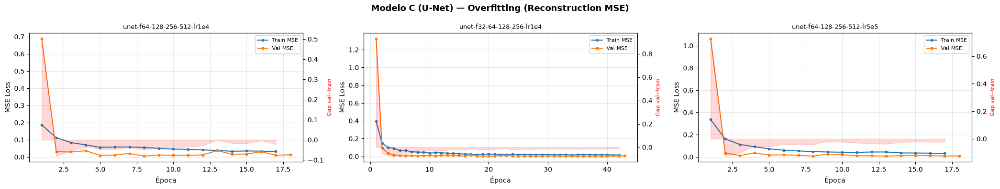

In [14]:
fig, axes = plt.subplots(1, len(results_c), figsize=(7 * len(results_c), 4))
if len(results_c) == 1:
    axes = [axes]

for ax, r in zip(axes, results_c):
    h = r['history']
    ax.plot(range(1, len(h.train_loss)+1), h.train_loss, label='Train MSE', marker='o', ms=3)
    ax.plot(range(1, len(h.val_loss)+1),   h.val_loss,   label='Val MSE',   marker='s', ms=3)
    n = min(len(h.train_loss), len(h.val_loss))
    gap = [v - t for t, v in zip(h.train_loss[:n], h.val_loss[:n])]
    ax2 = ax.twinx()
    ax2.fill_between(range(1, n+1), gap, alpha=0.15, color='red')
    ax2.set_ylabel('Gap val−train', color='red', fontsize=8)
    ax.set_title(r['run_name'], fontsize=9)
    ax.set_xlabel('Época'); ax.set_ylabel('MSE Loss')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.suptitle('Modelo C (U-Net) — Overfitting (Reconstruction MSE)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/overfitting_unet.png', dpi=150)
plt.show()

## 5 · Detección de Anomalías — Distancia de Mahalanobis

Comparación de los tres modelos usando:
1. **Distancia de Mahalanobis** sobre embeddings (modelos A, B y C)
2. **Error de reconstrucción MSE** (solo Modelo C)

**Metodología:**
1. Extraer embeddings del conjunto de validación (imágenes normales)
2. Estimar gaussiana por clase: µ y Σ
3. Score de anomalía = distancia mínima de Mahalanobis a cualquier clase
4. Umbral = percentil 95 de scores en validación

In [15]:
def find_best_ckpt(model_dir: str) -> str:
    ckpts = sorted(glob.glob(f'{model_dir}/**/*.ckpt', recursive=True))
    if not ckpts:
        raise FileNotFoundError(f'No checkpoint found in {model_dir}')
    def loss_from_name(p):
        try: return float(Path(p).stem.split('val_loss=')[-1])
        except: return float('inf')
    return sorted(ckpts, key=loss_from_name)[0]


# Datamodule compartido para evaluación
dm_eval = MVTecDataModule(
    dataset_path=DATASET_PATH, classes=CLASSES, image_size=IMAGE_SIZE,
    batch_size=64, num_workers=NUM_WORKERS, val_split=VAL_SPLIT,
)
dm_eval.setup()
print(f'Val samples:  {len(dm_eval.val_dataset)}')
print(f'Test samples: {len(dm_eval.test_dataset)}')

Val samples:  527
Test samples: 1236


In [16]:
# Cargar mejores checkpoints y extraer embeddings
ckpt_a = find_best_ckpt('../checkpoints/cnn_scratch')
print(f'Modelo A: {ckpt_a}')
model_a = CNNScratchModule.load_from_checkpoint(ckpt_a)
model_a.eval()
val_emb_a,  val_cls_a,  val_ano_a  = extract_embeddings(model_a, dm_eval.val_dataloader(),  DEVICE)
test_emb_a, test_cls_a, test_ano_a = extract_embeddings(model_a, dm_eval.test_dataloader(), DEVICE)
print(f'Embeddings A — val: {val_emb_a.shape} | test: {test_emb_a.shape}')

ckpt_b = find_best_ckpt('../checkpoints/cnn_distilled')
print(f'Modelo B: {ckpt_b}')
model_b = CNNDistilledModule.load_from_checkpoint(ckpt_b)
model_b.eval()
val_emb_b,  val_cls_b,  val_ano_b  = extract_embeddings(model_b, dm_eval.val_dataloader(),  DEVICE)
test_emb_b, test_cls_b, test_ano_b = extract_embeddings(model_b, dm_eval.test_dataloader(), DEVICE)
print(f'Embeddings B — val: {val_emb_b.shape} | test: {test_emb_b.shape}')

ckpt_c = find_best_ckpt('../checkpoints/unet')
print(f'Modelo C: {ckpt_c}')
model_c = UNetAutoencoderModule.load_from_checkpoint(ckpt_c)
model_c.eval()
val_err_c,  val_emb_c,  val_cls_c,  val_ano_c  = extract_recon_errors(model_c, dm_eval.val_dataloader(),  DEVICE)
test_err_c, test_emb_c, test_cls_c, test_ano_c = extract_recon_errors(model_c, dm_eval.test_dataloader(), DEVICE)
print(f'Embeddings C — val: {val_emb_c.shape} | test: {test_emb_c.shape}')
print(f'Anomalías en test: {test_ano_a.sum()} / {len(test_ano_a)}')

Modelo A: ../checkpoints/cnn_scratch/scratch-lr5e4-hd512/best-epoch=24-val_loss=0.0000.ckpt


Embeddings A — val: (527, 128) | test: (1236, 128)
Modelo B: ../checkpoints/cnn_distilled/distil-a5b3g2-lr1e3/best-epoch=30-val_loss=0.0004.ckpt


Embeddings B — val: (527, 128) | test: (1236, 128)
Modelo C: ../checkpoints/unet/unet-f32-64-128-256-lr1e4/best-epoch=38-val_loss=0.0026.ckpt


Embeddings C — val: (527, 128) | test: (1236, 128)
Anomalías en test: 925 / 1236


In [17]:
def mahal_pipeline(val_emb, val_cls, test_emb, test_cls, name):
    params      = fit_per_class_params(val_emb, val_cls)
    val_scores  = per_class_mahalanobis_scores(val_emb,  val_cls, params)
    test_scores = per_class_mahalanobis_scores(test_emb, test_cls, params)
    threshold   = find_threshold(val_scores, percentile=95)
    print(f'[{name}] Umbral P95: {threshold:.4f}')
    return val_scores, test_scores, threshold

val_sc_a,  test_sc_a,  thresh_a = mahal_pipeline(val_emb_a, val_cls_a, test_emb_a, test_cls_a, 'A (Scratch)')
val_sc_b,  test_sc_b,  thresh_b = mahal_pipeline(val_emb_b, val_cls_b, test_emb_b, test_cls_b, 'B (Destilado)')
val_sc_c,  test_sc_c,  thresh_c = mahal_pipeline(val_emb_c, val_cls_c, test_emb_c, test_cls_c, 'C (emb)')
thresh_recon = find_threshold(val_err_c, percentile=95)
print(f'[C recon] Umbral P95: {thresh_recon:.6f}')

[A (Scratch)] Umbral P95: 2169.8333
[B (Destilado)] Umbral P95: 295.9950
[C (emb)] Umbral P95: 326.8045
[C recon] Umbral P95: 0.006970


In [18]:
metrics = {
    'Modelo A (Scratch)':     evaluate_anomaly_detection(test_sc_a,  test_ano_a, thresh_a),
    'Modelo B (Destilado)':   evaluate_anomaly_detection(test_sc_b,  test_ano_b, thresh_b),
    'Modelo C (Mahal emb)':   evaluate_anomaly_detection(test_sc_c,  test_ano_c, thresh_c),
    'Modelo C (Recon error)': evaluate_anomaly_detection(test_err_c, test_ano_c, thresh_recon),
}

df_metrics = pd.DataFrame(metrics).T[['AUROC', 'AP', 'F1', 'Precision', 'Recall', 'Accuracy']]
print('\n=== Métricas de Detección de Anomalías ===')
print(df_metrics.round(4).to_string())


=== Métricas de Detección de Anomalías ===
                         AUROC      AP      F1  Precision  Recall  Accuracy
Modelo A (Scratch)      0.3652  0.6981  0.1728     0.7109  0.0984    0.2953
Modelo B (Destilado)    0.4531  0.7503  0.2298     0.8052  0.1341    0.3277
Modelo C (Mahal emb)    0.4125  0.7127  0.1142     0.6374  0.0627    0.2718
Modelo C (Recon error)  0.4899  0.7170  0.1070     0.5340  0.0595    0.2573


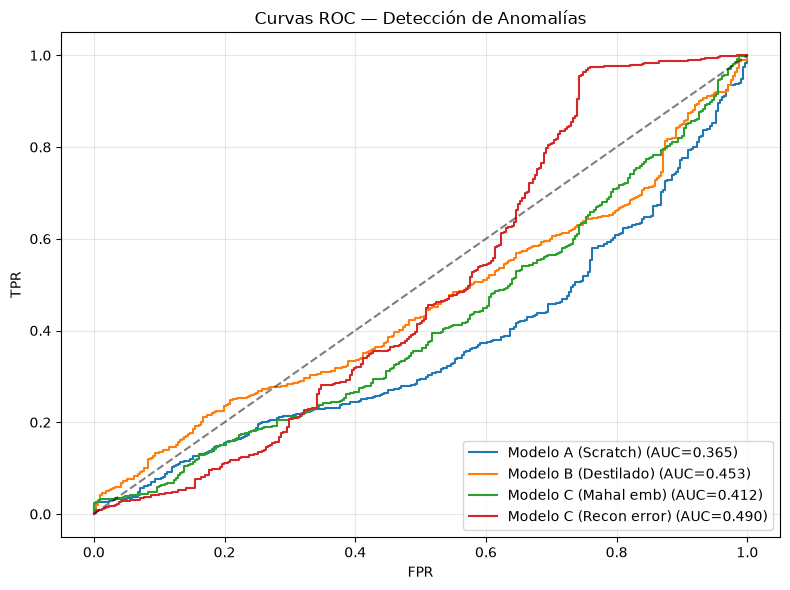

In [19]:
models_plot = [
    ('Modelo A (Scratch)',     test_sc_a,  test_ano_a),
    ('Modelo B (Destilado)',   test_sc_b,  test_ano_b),
    ('Modelo C (Mahal emb)',   test_sc_c,  test_ano_c),
    ('Modelo C (Recon error)', test_err_c, test_ano_c),
]

fig, ax = plt.subplots(figsize=(8, 6))
for name, scores, labels in models_plot:
    fpr, tpr, _ = get_roc_curve(scores, labels)
    ax.plot(fpr, tpr, label=f'{name} (AUC={metrics[name]["AUROC"]:.3f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.set_title('Curvas ROC — Detección de Anomalías')
ax.legend(loc='lower right'); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../outputs/roc_curves.png', dpi=150)
plt.show()

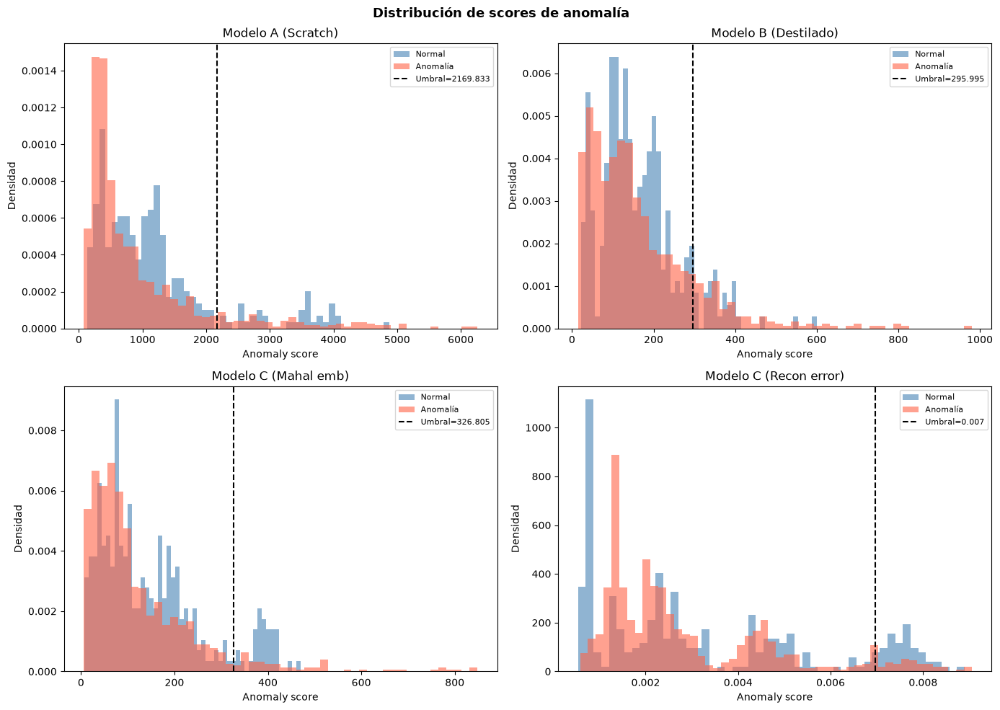


Mejor modelo: Modelo C (Recon error) — AUROC = 0.4899
|                        |   AUROC |     AP |     F1 |   Precision |   Recall |   Accuracy |
|:-----------------------|--------:|-------:|-------:|------------:|---------:|-----------:|
| Modelo A (Scratch)     |  0.3652 | 0.6981 | 0.1728 |      0.7109 |   0.0984 |     0.2953 |
| Modelo B (Destilado)   |  0.4531 | 0.7503 | 0.2298 |      0.8052 |   0.1341 |     0.3277 |
| Modelo C (Mahal emb)   |  0.4125 | 0.7127 | 0.1142 |      0.6374 |   0.0627 |     0.2718 |
| Modelo C (Recon error) |  0.4899 | 0.717  | 0.107  |      0.534  |   0.0595 |     0.2573 |


In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (name, scores, labels) in zip(axes.flat, models_plot):
    ax.hist(scores[labels == 0], bins=50, alpha=0.6, label='Normal',   color='steelblue', density=True)
    ax.hist(scores[labels == 1], bins=50, alpha=0.6, label='Anomalía', color='tomato',    density=True)
    t = metrics[name]['Threshold']
    ax.axvline(t, color='k', linestyle='--', label=f'Umbral={t:.3f}')
    ax.set_title(name); ax.legend(fontsize=8)
    ax.set_xlabel('Anomaly score'); ax.set_ylabel('Densidad')
plt.suptitle('Distribución de scores de anomalía', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/score_distributions.png', dpi=150)
plt.show()

best_model_name = df_metrics['AUROC'].idxmax()
print(f'\nMejor modelo: {best_model_name} — AUROC = {df_metrics.loc[best_model_name, "AUROC"]:.4f}')
print(df_metrics.round(4).to_markdown())

## 6 · Análisis de Outliers con DBSCAN — PCA y t-SNE

Usando el espacio latente de los tres modelos:
1. Reducir dimensionalidad con **PCA** y **t-SNE**
2. Aplicar **DBSCAN** — los puntos *noise* (label=-1) se interpretan como anomalías
3. Comparar clustering con etiquetas reales de anomalía

Reducción PCA...


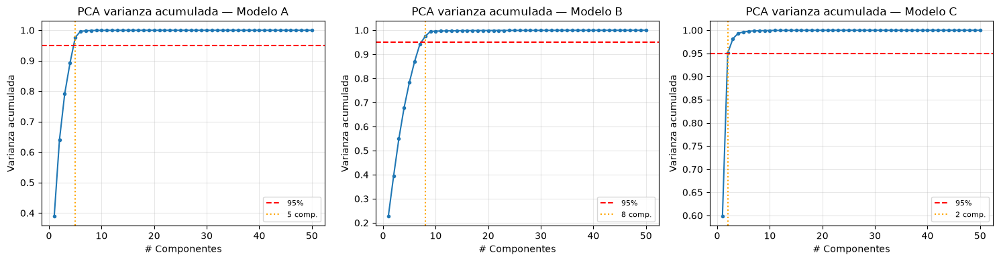

In [21]:
# PCA — varianza explicada
print('Reducción PCA...')
pca_data_a, pca_a = reduce_pca(test_emb_a, n_components=min(50, test_emb_a.shape[1]))
pca_data_b, pca_b = reduce_pca(test_emb_b, n_components=min(50, test_emb_b.shape[1]))
pca_data_c, pca_c = reduce_pca(test_emb_c, n_components=min(50, test_emb_c.shape[1]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, pca, name in zip(axes, [pca_a, pca_b, pca_c], ['Modelo A', 'Modelo B', 'Modelo C']):
    cumvar = np.cumsum(pca.explained_variance_ratio_)
    ax.plot(range(1, len(cumvar)+1), cumvar, marker='o', ms=3)
    ax.axhline(0.95, color='red', linestyle='--', label='95%')
    n95 = int(np.searchsorted(cumvar, 0.95)) + 1
    ax.axvline(n95, color='orange', linestyle=':', label=f'{n95} comp.')
    ax.set_title(f'PCA varianza acumulada — {name}')
    ax.set_xlabel('# Componentes'); ax.set_ylabel('Varianza acumulada')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../outputs/pca_explained_variance.png', dpi=150)
plt.show()

pca_2d_a = pca_data_a[:, :2]
pca_2d_b = pca_data_b[:, :2]
pca_2d_c = pca_data_c[:, :2]

In [22]:
# t-SNE (puede tardar varios minutos)
print('Calculando t-SNE — puede tardar...')
tsne_2d_a = reduce_tsne(test_emb_a, pca_first=True)
tsne_2d_b = reduce_tsne(test_emb_b, pca_first=True)
tsne_2d_c = reduce_tsne(test_emb_c, pca_first=True)
print('t-SNE listo.')

Calculando t-SNE — puede tardar...


t-SNE listo.


In [23]:
# DBSCAN con búsqueda de hiperparámetros (silhouette score)
print('Optimizando DBSCAN...')
dbscan_results = {}

for name, pca_2d, tsne_2d, ano_labels in [
    ('Modelo A', pca_2d_a, tsne_2d_a, test_ano_a),
    ('Modelo B', pca_2d_b, tsne_2d_b, test_ano_b),
    ('Modelo C', pca_2d_c, tsne_2d_c, test_ano_c),
]:
    eps_p, ms_p, _ = tune_dbscan(pca_2d)
    dbscan_pca     = run_dbscan(pca_2d,  eps=eps_p, min_samples=ms_p)
    eps_t, ms_t, _ = tune_dbscan(tsne_2d)
    dbscan_tsne    = run_dbscan(tsne_2d, eps=eps_t, min_samples=ms_t)

    metrics_pca  = dbscan_anomaly_metrics(dbscan_pca,  ano_labels)
    metrics_tsne = dbscan_anomaly_metrics(dbscan_tsne, ano_labels)

    dbscan_results[name] = {
        'pca_2d': pca_2d, 'tsne_2d': tsne_2d,
        'dbscan_pca': dbscan_pca, 'dbscan_tsne': dbscan_tsne,
        'metrics_pca': metrics_pca, 'metrics_tsne': metrics_tsne,
        'ano_labels': ano_labels,
        'eps_pca': eps_p, 'ms_pca': ms_p, 'eps_tsne': eps_t, 'ms_tsne': ms_t,
    }
    print(f'[{name}] PCA  eps={eps_p} ms={ms_p} → F1={metrics_pca["F1"]:.3f} | '
          f't-SNE eps={eps_t} ms={ms_t} → F1={metrics_tsne["F1"]:.3f}')

Optimizando DBSCAN...


[Modelo A] PCA  eps=0.5 ms=15 → F1=0.088 | t-SNE eps=0.3 ms=5 → F1=0.860


[Modelo B] PCA  eps=0.3 ms=3 → F1=0.000 | t-SNE eps=0.3 ms=5 → F1=0.855


[Modelo C] PCA  eps=0.3 ms=15 → F1=0.006 | t-SNE eps=1.0 ms=15 → F1=0.846


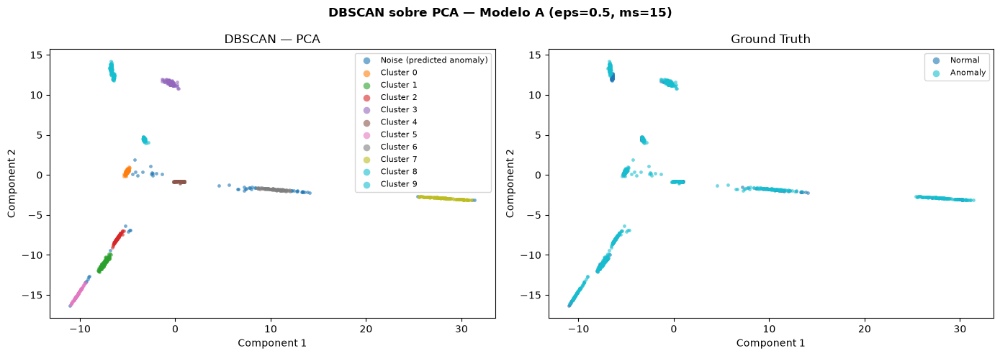

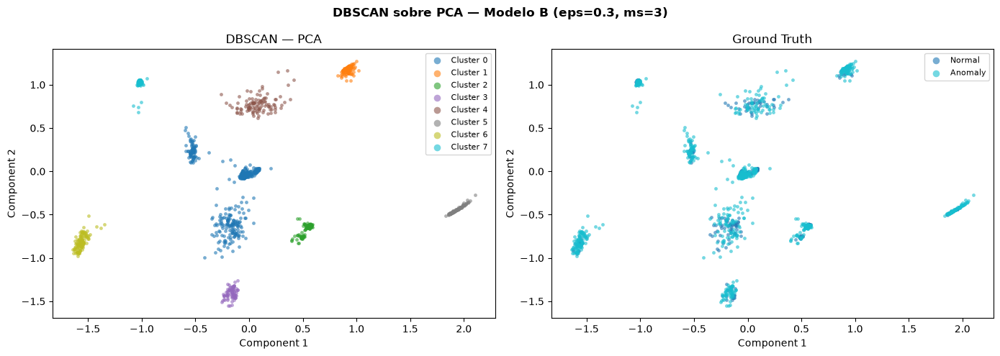

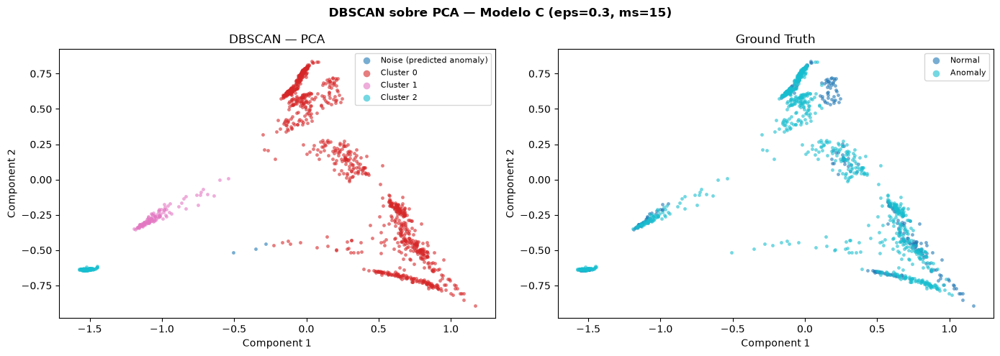

In [24]:
# Visualizaciones PCA + DBSCAN
for name, res in dbscan_results.items():
    fig = plot_2d_embeddings(
        embeddings_2d=res['pca_2d'], dbscan_labels=res['dbscan_pca'],
        true_anomaly_labels=res['ano_labels'], method='PCA', figsize=(14, 5),
    )
    fig.suptitle(f'DBSCAN sobre PCA — {name} (eps={res["eps_pca"]}, ms={res["ms_pca"]})',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'../outputs/dbscan_pca_{name.lower().replace(" ", "_")}.png', dpi=150)
    plt.show()

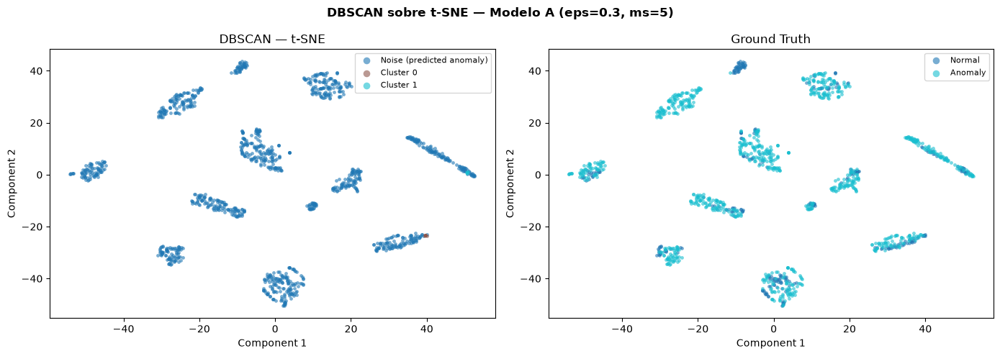

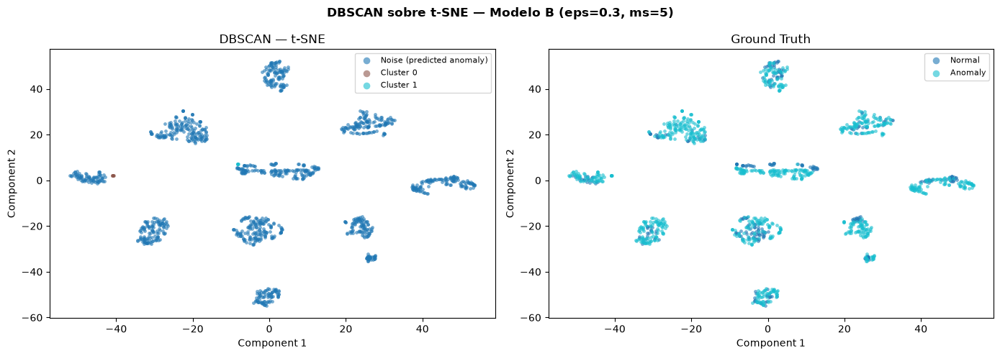

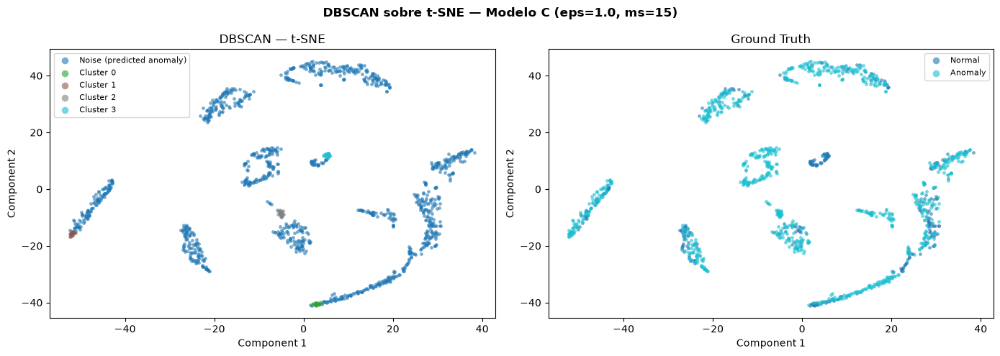

In [25]:
# Visualizaciones t-SNE + DBSCAN
for name, res in dbscan_results.items():
    fig = plot_2d_embeddings(
        embeddings_2d=res['tsne_2d'], dbscan_labels=res['dbscan_tsne'],
        true_anomaly_labels=res['ano_labels'], method='t-SNE', figsize=(14, 5),
    )
    fig.suptitle(f'DBSCAN sobre t-SNE — {name} (eps={res["eps_tsne"]}, ms={res["ms_tsne"]})',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'../outputs/dbscan_tsne_{name.lower().replace(" ", "_")}.png', dpi=150)
    plt.show()

In [26]:
# Tabla comparativa cuantitativa
rows = []
for name, res in dbscan_results.items():
    for method, key in [('PCA', 'metrics_pca'), ('t-SNE', 'metrics_tsne')]:
        m = res[key]
        rows.append({
            'Modelo': name, 'Reducción': method,
            'n_clusters': m['n_clusters'], 'noise_rate': f"{m['noise_rate']:.2%}",
            'Precision': f"{m['Precision']:.3f}", 'Recall': f"{m['Recall']:.3f}",
            'F1': f"{m['F1']:.3f}", 'Accuracy': f"{m['Accuracy']:.3f}",
        })

df_dbscan = pd.DataFrame(rows)
print('\n=== Análisis DBSCAN — Detección de Outliers ===')
print(df_dbscan.to_string(index=False))
df_dbscan.to_csv('../outputs/dbscan_metrics.csv', index=False)


=== Análisis DBSCAN — Detección de Outliers ===
  Modelo Reducción  n_clusters noise_rate Precision Recall    F1 Accuracy
Modelo A       PCA          10      4.37%     0.796  0.046 0.088    0.278
Modelo A     t-SNE           2     99.11%     0.754  0.999 0.860    0.756
Modelo B       PCA           8      0.00%     0.000  0.000 0.000    0.252
Modelo B     t-SNE           2     99.11%     0.750  0.994 0.855    0.748
Modelo C       PCA           3      0.24%     1.000  0.003 0.006    0.254
Modelo C     t-SNE           4     94.66%     0.757  0.958 0.846    0.739


## Interpretación

- **Clusters DBSCAN vs ground truth**: Los puntos de ruido (label=-1) deberían correlacionar con anomalías reales. Un buen modelo produce clusters densos para imágenes normales y puntos dispersos para anomalías.
- **PCA vs t-SNE**: PCA preserva estructura global (varianza); t-SNE preserva estructura local (vecindades), lo que suele hacer más visibles los grupos separados.
- **Comparación de modelos**: El modelo con mayor separación visual normal/anomalía y mayor F1 en DBSCAN captura mejor la distribución latente de lo normal.